In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split

In [3]:
df = pd.read_csv('WA_Fn-UseC_-Telco-Customer-Churn.csv')

In [4]:
df

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
7038,6840-RESVB,Male,0,Yes,Yes,24,Yes,Yes,DSL,Yes,...,Yes,Yes,Yes,Yes,One year,Yes,Mailed check,84.80,1990.5,No
7039,2234-XADUH,Female,0,Yes,Yes,72,Yes,Yes,Fiber optic,No,...,Yes,No,Yes,Yes,One year,Yes,Credit card (automatic),103.20,7362.9,No
7040,4801-JZAZL,Female,0,Yes,Yes,11,No,No phone service,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.60,346.45,No
7041,8361-LTMKD,Male,1,Yes,No,4,Yes,Yes,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Mailed check,74.40,306.6,Yes


In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [6]:
df.duplicated().sum()

np.int64(0)

In [7]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [8]:
cols=df.drop(columns="customerID").columns
for col in cols:
  print("columns",col,df[col].unique())

columns gender ['Female' 'Male']
columns SeniorCitizen [0 1]
columns Partner ['Yes' 'No']
columns Dependents ['No' 'Yes']
columns tenure [ 1 34  2 45  8 22 10 28 62 13 16 58 49 25 69 52 71 21 12 30 47 72 17 27
  5 46 11 70 63 43 15 60 18 66  9  3 31 50 64 56  7 42 35 48 29 65 38 68
 32 55 37 36 41  6  4 33 67 23 57 61 14 20 53 40 59 24 44 19 54 51 26  0
 39]
columns PhoneService ['No' 'Yes']
columns MultipleLines ['No phone service' 'No' 'Yes']
columns InternetService ['DSL' 'Fiber optic' 'No']
columns OnlineSecurity ['No' 'Yes' 'No internet service']
columns OnlineBackup ['Yes' 'No' 'No internet service']
columns DeviceProtection ['No' 'Yes' 'No internet service']
columns TechSupport ['No' 'Yes' 'No internet service']
columns StreamingTV ['No' 'Yes' 'No internet service']
columns StreamingMovies ['No' 'Yes' 'No internet service']
columns Contract ['Month-to-month' 'One year' 'Two year']
columns PaperlessBilling ['Yes' 'No']
columns PaymentMethod ['Electronic check' 'Mailed check' 'Ban

In [9]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce')

In [10]:
df['TotalCharges'].isnull().sum()

np.int64(11)

In [11]:
df.dropna(subset=['TotalCharges'], inplace=True)

In [12]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 7032 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7032 non-null   object 
 1   gender            7032 non-null   object 
 2   SeniorCitizen     7032 non-null   int64  
 3   Partner           7032 non-null   object 
 4   Dependents        7032 non-null   object 
 5   tenure            7032 non-null   int64  
 6   PhoneService      7032 non-null   object 
 7   MultipleLines     7032 non-null   object 
 8   InternetService   7032 non-null   object 
 9   OnlineSecurity    7032 non-null   object 
 10  OnlineBackup      7032 non-null   object 
 11  DeviceProtection  7032 non-null   object 
 12  TechSupport       7032 non-null   object 
 13  StreamingTV       7032 non-null   object 
 14  StreamingMovies   7032 non-null   object 
 15  Contract          7032 non-null   object 
 16  PaperlessBilling  7032 non-null   object 
 17  

In [13]:
df.drop('customerID', axis=1, inplace=True)

In [14]:
df.replace({
    "gender": {"Male": 1, "Female": 0},
    "Partner": {"Yes": 1, "No": 0},
    "Dependents": {"Yes": 1, "No": 0},
    "PhoneService": {"Yes": 1, "No": 0},
    "PaperlessBilling": {"Yes": 1, "No": 0},
    "Churn": {"Yes": 1, "No": 0}
}, inplace=True)

C:\Users\frndas\AppData\Local\Temp\ipykernel_14128\725494666.py:1: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  df.replace({


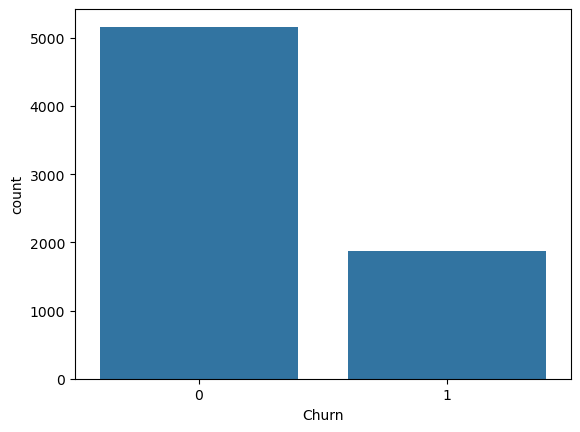

In [15]:
sns.countplot(data=df, x='Churn')
plt.show()

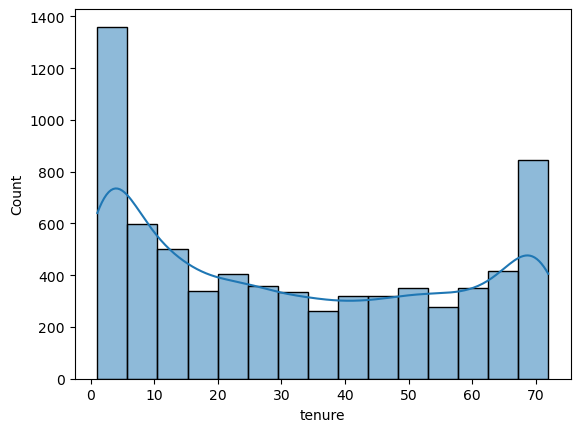

In [16]:
sns.histplot(data=df, x='tenure', kde=True)
plt.show()

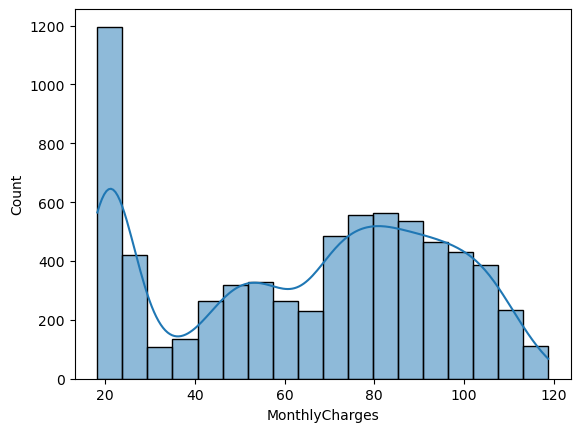

In [17]:
sns.histplot(data=df, x='MonthlyCharges', kde=True)
plt.show()

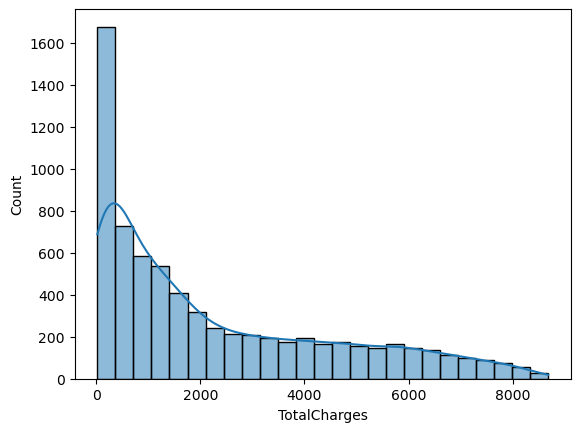

In [18]:
sns.histplot(data=df, x='TotalCharges', kde=True)
plt.show()

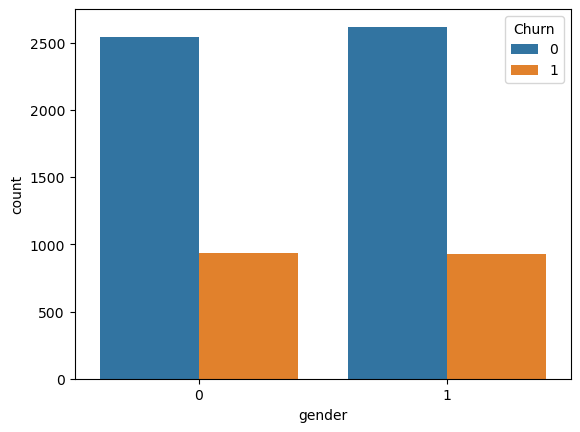

In [19]:
sns.countplot(data=df, x='gender', hue='Churn')
plt.show()

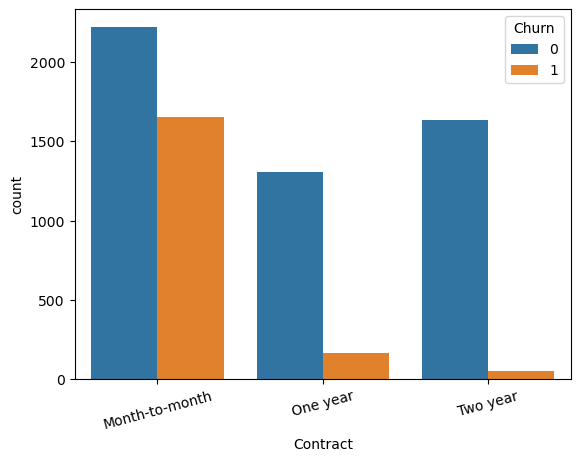

In [20]:
sns.countplot(data=df, x='Contract', hue='Churn')
plt.xticks(rotation=15)
plt.show()

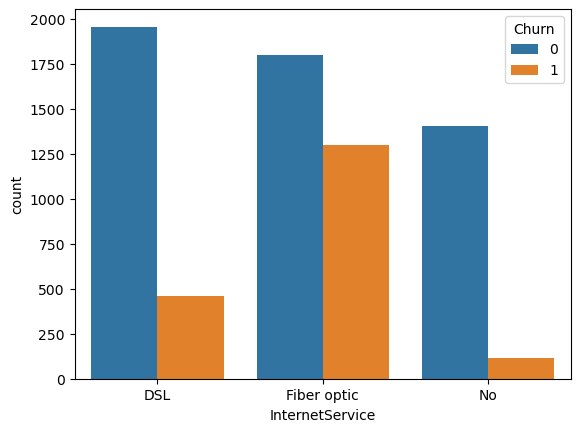

In [21]:
sns.countplot(data=df, x='InternetService', hue='Churn')
plt.show()

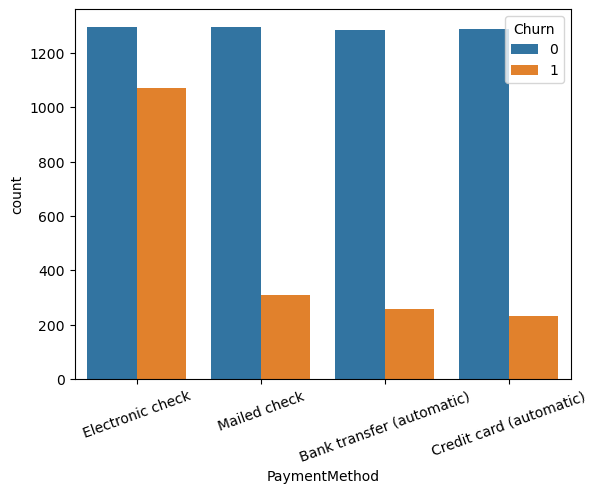

In [22]:
sns.countplot(data=df, x='PaymentMethod', hue='Churn')
plt.xticks(rotation=20)
plt.show()

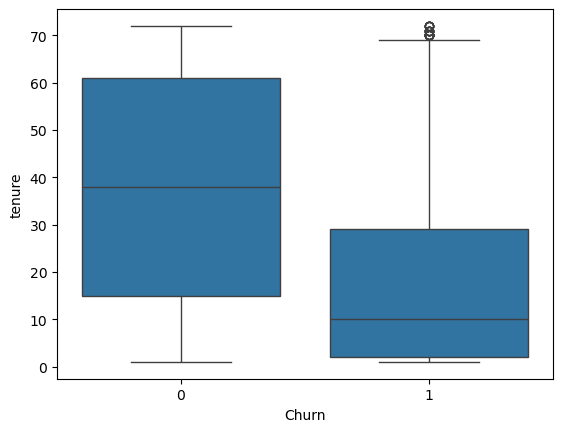

In [23]:
sns.boxplot(data=df, x='Churn', y='tenure')
plt.show()

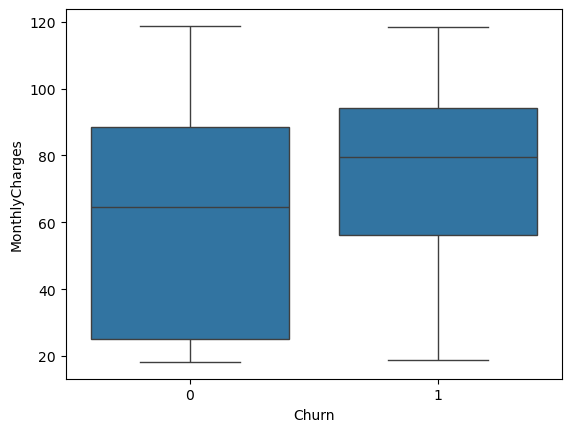

In [24]:
sns.boxplot(data=df, x='Churn', y='MonthlyCharges')
plt.show()

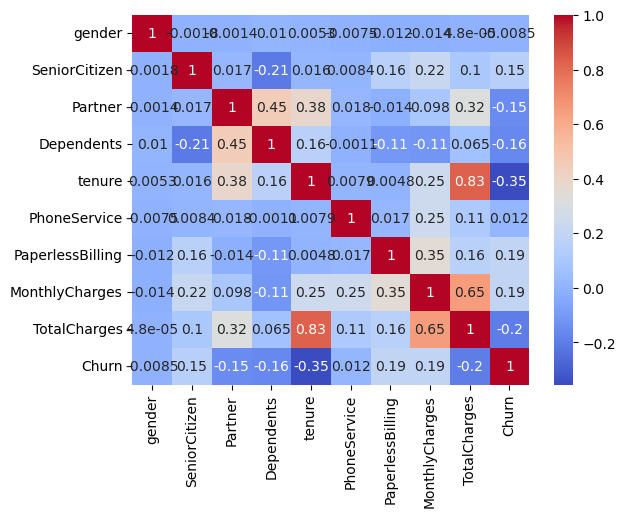

In [25]:
num_df = df.select_dtypes(include='number')

sns.heatmap(num_df.corr(), annot=True, cmap='coolwarm')
plt.show()

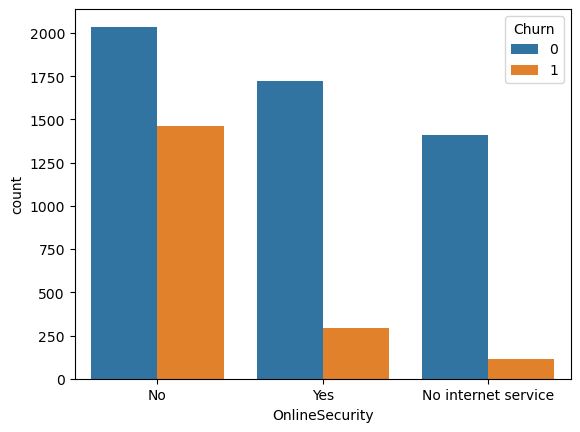

In [26]:
sns.countplot(data=df, x='OnlineSecurity', hue='Churn')
plt.show()

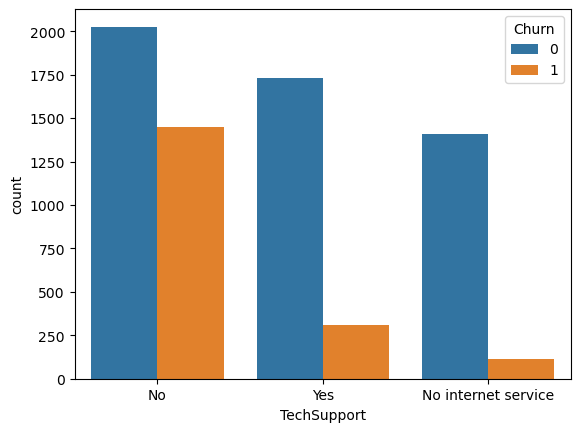

In [27]:
sns.countplot(data=df, x='TechSupport', hue='Churn')
plt.show()

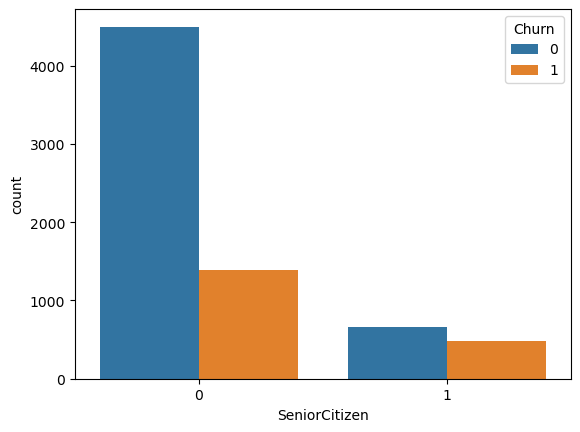

In [28]:
sns.countplot(data=df, x='SeniorCitizen', hue='Churn')
plt.show()

In [29]:
x = df.drop(columns='Churn')
y = df['Churn']

In [30]:
%pip install imbalanced-learn

Note: you may need to restart the kernel to use updated packages.


In [31]:
print(type(y))
print(y.dtype)
print(y.head())
print(y.unique())

<class 'pandas.core.series.Series'>
int64
0    0
1    0
2    1
3    0
4    1
Name: Churn, dtype: int64
[0 1]


In [ ]:
y = y.astype(int)

x_train, x_test, y_train, y_test = train_test_split(
    x, y, test_size=0.2, random_state=42, stratify=y
)




In [33]:
##pip install imblearn

In [34]:
from imblearn.over_sampling import RandomOverSampler
ros = RandomOverSampler(random_state=42)
x_train, y_train = ros.fit_resample(x_train, y_train)

print(y_train.value_counts())
print(y_test.value_counts())

Churn
0    4130
1    4130
Name: count, dtype: int64
Churn
0    1033
1     374
Name: count, dtype: int64


In [35]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [36]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

# Separate numerical and categorical columns
num_cols = x_train.select_dtypes(include="number").columns
cat_cols = x_train.select_dtypes(exclude="number").columns

# Apply the appropriate transformation to each type
preprocessor = ColumnTransformer([
    ("num", StandardScaler(), num_cols),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols)
])

X_train_processed = preprocessor.fit_transform(x_train)
X_test_processed = preprocessor.transform(x_test)


In [37]:
from sklearn.linear_model import LogisticRegression
model = LogisticRegression(random_state=42)

In [38]:
df.head()

,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,0,0,1,0,1,0,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,1,Electronic check,29.85,29.85,0
1,1,0,0,0,34,1,No,DSL,Yes,No,Yes,No,No,No,One year,0,Mailed check,56.95,1889.50,0
2,1,0,0,0,2,1,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,1,Mailed check,53.85,108.15,1
3,1,0,0,0,45,0,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,0,Bank transfer (automatic),42.30,1840.75,0
4,0,0,0,0,2,1,No,Fiber optic,No,No,No,No,No,No,Month-to-month,1,Electronic check,70.70,151.65,1


In [39]:
print(y_train.dtypes)
print(y_train.head())

int64
0    0
1    0
2    0
3    0
4    0
Name: Churn, dtype: int64


In [40]:
y_train = y_train.astype(int)
y_test = y_test.astype(int)

In [41]:
model.fit(X_train_processed, y_train)

,penalty,'l2'
,dual,False
,tol,0.0001
,C,1.0
,fit_intercept,True
,intercept_scaling,1
,class_weight,None
,random_state,42
,solver,'lbfgs'
,max_iter,100
,multi_class,'deprecated'


In [42]:
y_pred = model.predict(X_test_processed)

In [43]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
confusion_matrix = pd.crosstab(y_test, y_pred, rownames=['Actual'], colnames=['Predicted'])
accuracy = accuracy_score(y_test, y_pred)
classification_report = classification_report(y_test, y_pred)
print("\nAccuracy:", accuracy)
print("\nClassification Report:\n", classification_report)


Accuracy: 0.7256574271499645

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.70      0.79      1033
           1       0.49      0.80      0.61       374

    accuracy                           0.73      1407
   macro avg       0.70      0.75      0.70      1407
weighted avg       0.79      0.73      0.74      1407



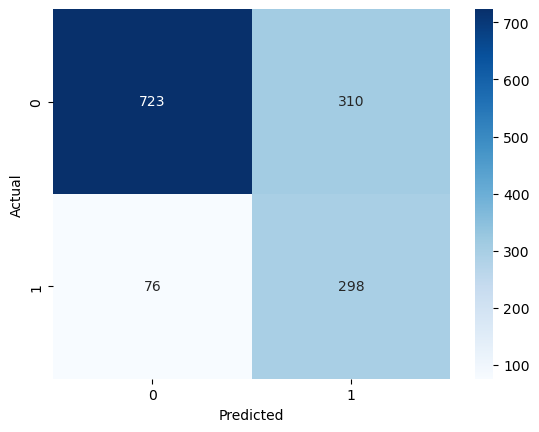

In [44]:
heatmap = sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues')

In [45]:
from sklearn.ensemble import RandomForestClassifier
rf = RandomForestClassifier(n_estimators=100, max_depth=10, random_state=42)

In [46]:
rf.fit(X_train_processed, y_train)

,n_estimators,100
,criterion,'gini'
,max_depth,10
,min_samples_split,2
,min_samples_leaf,1
,min_weight_fraction_leaf,0.0
,max_features,'sqrt'
,max_leaf_nodes,None
,min_impurity_decrease,0.0
,bootstrap,True
,oob_score,False


In [47]:
y_pred1 = rf.predict(X_test_processed)

In [48]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
confusion_matrix = pd.crosstab(y_test, y_pred1, rownames=['Actual'], colnames=['Predicted'])
accuracy = accuracy_score(y_test, y_pred1)
classification_report = classification_report(y_test, y_pred1)
print("\nAccuracy:", accuracy)
print("\nClassification Report:\n", classification_report)


Accuracy: 0.7555081734186212

Classification Report:
               precision    recall  f1-score   support

           0       0.90      0.76      0.82      1033
           1       0.53      0.76      0.62       374

    accuracy                           0.76      1407
   macro avg       0.71      0.76      0.72      1407
weighted avg       0.80      0.76      0.77      1407



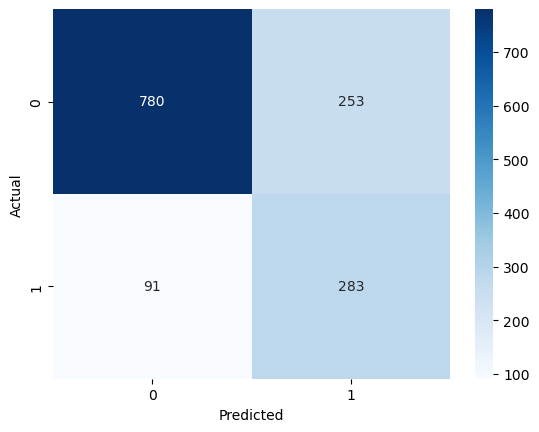

In [49]:
heatmap = sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues')

In [50]:
%pip install xgboost

Note: you may need to restart the kernel to use updated packages.


In [51]:
from xgboost import XGBClassifier

xgb = XGBClassifier(
    n_estimators=100,
    max_depth=10,
    random_state=42,
    eval_metric="logloss"
)

xgb.fit(X_train_processed, y_train)

,objective,'binary:logistic'
,base_score,None
,booster,None
,callbacks,None
,colsample_bylevel,None
,colsample_bynode,None
,colsample_bytree,None
,device,None
,early_stopping_rounds,None
,enable_categorical,True
,eval_metric,'logloss'


In [52]:
y_pred2 = xgb.predict(X_test_processed)

In [53]:
from sklearn.metrics import confusion_matrix, classification_report, accuracy_score
confusion_matrix = pd.crosstab(y_test, y_pred2, rownames=['Actual'], colnames=['Predicted'])
accuracy = accuracy_score(y_test, y_pred2)
classification_report = classification_report(y_test, y_pred2)
print("\nAccuracy:", accuracy)
print("\nClassification Report:\n", classification_report)


Accuracy: 0.746268656716418

Classification Report:
               precision    recall  f1-score   support

           0       0.84      0.81      0.82      1033
           1       0.52      0.57      0.55       374

    accuracy                           0.75      1407
   macro avg       0.68      0.69      0.68      1407
weighted avg       0.75      0.75      0.75      1407



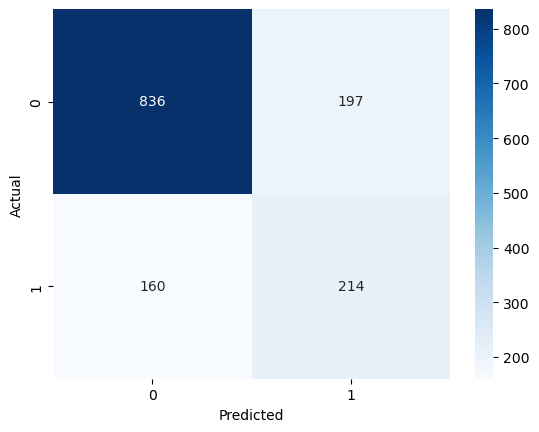

In [54]:
heatmap = sns.heatmap(confusion_matrix, annot=True, fmt='d', cmap='Blues')